# YZM 411 Bilgisayarlı Görü — Ödev 1: Renk, Aydınlatma ve Örnekleme

**Öğrenci:** Muhammed Emin Erdağ — **No:** 230212013

Bu defter, kendi kurduğum masaüstü sahnesinin üç fotoğrafı (normal ışık, gölge, farklı lamba) üzerinde dört deneyi çalıştırır.
Her deneyden **önce** yazılmış tahmin, ardından ölçüm ve en sonda *“Ne gördüm, neden olabilir, nasıl kontrol ederim?”* yanıtı bulunur.

**Çalıştırma sırası:** `Kernel → Restart & Run All` (hücreler yukarıdan aşağı sırayla çalışır; hiçbir hücre elle atlanmamalıdır).

| Bölüm | İçerik | Hedef |
|---|---|---|
| 0 | Paket sürümleri, parametreler, giriş dosyaları, EXIF ve kamera sabitliği kontrolü | — |
| 1 | Görüntünün sayısal yapısı, `img[y, x, kanal]`, BGR→RGB, 3 pikselin değerleri | H1 |
| 2 | Dondurulmuş RGB / HSV eşikleri, 6 maske, alan oranları | H2 |
| 3 | Parlaklık kaydırması (b = +40) ve gama (γ = 0,5 / 2,0) | H3 |
| 4 | 1/4 küçültme: `INTER_NEAREST` ve `INTER_AREA` | H4 |
| 5 | Tahmin–ölçüm özet tablosu, sonuç dosyaları | — |

**Girdi dosyaları:** `data/normal.jpg`, `data/golge.jpg`, `data/lamba.jpg`
**Çıktılar:** `outputs/*.png` (şekiller), `results/*.csv` ve `results/olcumler.json` (ham ölçümler)

## 0. Ortam ve parametreler

In [1]:
import json, platform, sys
from pathlib import Path

import cv2
import matplotlib
if "ipykernel" not in sys.modules:      # odev1.py olarak komut satırından çalıştırılırsa
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
from PIL import ExifTags, Image

print("Python     :", sys.version.split()[0], "|", platform.platform())
print("NumPy      :", np.__version__)
print("OpenCV     :", cv2.__version__)
print("Matplotlib :", matplotlib.__version__)
print("pandas     :", pd.__version__)
print("Pillow     :", PIL.__version__)

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 9})
try:
    display
except NameError:                        # Jupyter dışında display() yoksa tabloları print ile yaz
    display = print
MEAS = {}  # tüm ham ölçümler buraya yazılır ve sonunda results/olcumler.json olarak kaydedilir

Python     : 3.13.12 | Windows-11-10.0.26200-SP0
NumPy      : 2.4.4
OpenCV     : 5.0.0
Matplotlib : 3.10.9
pandas     : 3.0.2
Pillow     : 12.2.0


### Parametreler
Tüm sabitler bu hücrededir. Eşikler **yalnızca normal ışıklı fotoğraftan** belirlenmiş ve aşağıya elle yazılarak **dondurulmuştur**;
gölge ve lamba fotoğrafları için yeniden ayarlanmamıştır. Koordinatlar `(x, y)` = (sütun, satır) biçimindedir.

In [2]:
DATA_DIR = Path("data")
FILES = {"normal": "normal.jpg", "golge": "golge.jpg", "lamba": "lamba.jpg"}
NAMES_TR = {"normal": "Normal ışık", "golge": "Gölge", "lamba": "Farklı lamba"}
# Özgün dosya adları: normal = 20261109_200628.jpg, gölge = 20261109_200638.jpg, lamba = 20261109_200618.jpg

# Kamera ayarları hakkında not (EXIF ile birlikte rapora geçer)
CAMERA_NOTE = ("Samsung Galaxy A54 5G ana kamera; otomatik pozlama ve otomatik beyaz dengesi AÇIK, flaş kapalı. "
               "Telefon çekimler arasında hafifçe kaydı; gölge ve lamba fotoğrafları normal fotoğrafa homografi ile hizalandı. "
               "Bu nedenle 'yalnızca ışık değişti' denemez: kamera kazancı ve renk dengesi de değişti.")

# H1: hedef nesne = turuncu kumaş kalemlik. Üzerindeki aynı fiziksel bölgelerden 3 piksel, (x, y)
PIXELS = [(1250, 1850), (1650, 2300), (1400, 2900)]
NEIGH = 2                      # piksel çevresinde (2*NEIGH+1)^2 = 5x5 ortalama da raporlanır

# H2: eşik türetmek için normal ışıktaki küçük nesne bölgesi ve tüm nesnenin kutusu (x, y, w, h)
OBJ_ROI = (1350, 2000, 250, 250)
OBJ_BOX = (1090, 1580, 790, 1680)  # yalnızca tanı amaçlı: seçilen piksellerin kalemlik kutusu içinde/dışında dağılımı

# H2: DONDURULMUŞ eşikler (normal ışıktaki OBJ_ROI'nin yüzde 2-98 aralığı + pay, bkz. 2.1; yuvarlanarak elle yazıldı)
RGB_LO, RGB_HI = (115, 30, 0), (230, 145, 95)      # (R, G, B)
HSV_LO, HSV_HI = (5, 125, 80), (16, 255, 255)      # OpenCV 8 bit: H 0-179, S ve V 0-255

# H3
B_SHIFT = 40
GAMMAS = (0.5, 2.0)

# H4: iskambil kartındaki küçük yazı + karo dokusu (normal ışık), küçültme oranı
TEXT_ROI = (348, 1900, 400, 400)
FACTOR = 4

# H4 gösterim: kesit içinde yakınlaştırılacak alt bölge (x, y, w, h) — "MADE IN U.S.A." satırı
TEXT_ZOOM = (60, 230, 160, 160)

# H2 tanı: seçilen piksellerin geldiği bölgeler (x, y, w, h), normal karede elle çizildi
REGIONS = {
    "kalemlik": OBJ_BOX,
    "kupa (çay)": (180, 2780, 900, 1020),
    "kitap": (160, 400, 1510, 990),
    "üst ahşap": (0, 0, 1884, 380),
}

### Giriş dosyaları, EXIF ve kamera sabitliği kontrolü
Otomatik pozlama veya otomatik beyaz dengesi açıksa, fotoğraflar arasındaki fark **yalnızca ışıktan** kaynaklanmaz;
kamera da kazancını/renk dengesini değiştirmiş olabilir. Bunu EXIF'ten okuyorum. Telefon çekimler arasında
biraz kaydığı/yakınlaştığı için gölge ve lamba fotoğraflarını normal fotoğrafa hizalıyorum (aynı (x, y) koordinatının aynı fiziksel noktaya denk gelmesi için gerekli).

In [3]:
def find_file(key):
    p = DATA_DIR / FILES[key]
    if p.exists():
        return p
    cands = sorted(DATA_DIR.glob(Path(FILES[key]).stem + ".*"))
    if not cands:
        raise FileNotFoundError(f"{p} bulunamadı. Fotoğrafları data/ klasörüne koyun.")
    return cands[0]

PATHS = {k: find_file(k) for k in FILES}
orig_bgr = {k: cv2.imread(str(p), cv2.IMREAD_COLOR) for k, p in PATHS.items()}   # OpenCV: BGR sırası, EXIF yönü uygulanır
for k, im in orig_bgr.items():
    assert im is not None, f"{PATHS[k]} okunamadı"
    print(f"{PATHS[k].name:11s} shape={im.shape} dtype={im.dtype}")
H, W, C = orig_bgr["normal"].shape

EXP_MODE = {0: "otomatik", 1: "manuel", 2: "otomatik braket"}
WB_MODE = {0: "otomatik", 1: "manuel"}

def exif_info(path):
    d = {}
    try:
        ex = Image.open(path).getexif()
        d.update({ExifTags.TAGS.get(k, k): v for k, v in ex.items()})
        d.update({ExifTags.TAGS.get(k, k): v for k, v in ex.get_ifd(0x8769).items()})
    except Exception as e:
        d["hata"] = str(e)
    et = d.get("ExposureTime")
    return {
        "dosya": path.name,
        "cihaz": f'{d.get("Make", "-")} {d.get("Model", "-")}'.strip(),
        "pozlama süresi (s)": (f"1/{round(1/float(et))}" if et and float(et) < 1 else str(et)) if et else "-",
        "ISO": d.get("ISOSpeedRatings", d.get("PhotographicSensitivity", "-")),
        "f": d.get("FNumber", "-"),
        "pozlama modu": EXP_MODE.get(d.get("ExposureMode"), "-"),
        "beyaz dengesi": WB_MODE.get(d.get("WhiteBalance"), "-"),
        "flaş": d.get("Flash", "-"),
        "tarih": d.get("DateTimeOriginal", "-"),
    }

exif_df = pd.DataFrame({NAMES_TR[k]: exif_info(p) for k, p in PATHS.items()})
# pozlama süresi x ISO: kameranın sahneye uyguladığı toplam kazanç; büyükse sahne daha karanlık algılanmıştır
def t_iso(path):
    ex = Image.open(path).getexif().get_ifd(0x8769)
    t, iso = ex.get(0x829A), ex.get(0x8827)
    return float(t) * float(iso) if t and iso else float("nan")
TISO = {k: t_iso(p) for k, p in PATHS.items()}
exif_df.loc["süre×ISO (normal=1)"] = [round(TISO[k] / TISO["normal"], 2) for k in FILES]
display(exif_df)
exif_df.to_csv(RES / "exif.csv", encoding="utf-8-sig")
MEAS["exif"] = exif_df.astype(str).to_dict()
MEAS["camera_note"] = CAMERA_NOTE
print("Kamera notu:", CAMERA_NOTE)

# Kamera sabitliği: fotoğraflar elde/dayanakla çekildiği için çekimler arasında küçük kayma ve ölçek farkı olabilir.
# SIFT öznitelikleri + RANSAC ile her fotoğraftan normal'e bir homografi kestiriyorum.
sift = cv2.SIFT_create(8000)
clahe = cv2.createCLAHE(2.0, (8, 8))   # yalnızca öznitelik bulmak için; ölçümler özgün piksellerden yapılır

def feats(im):
    g = cv2.cvtColor(cv2.resize(im, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    return sift.detectAndCompute(clahe.apply(g), None)

S2 = np.diag([2.0, 2.0, 1.0])
kp0, de0 = feats(orig_bgr["normal"])
HOMS = {"normal": np.eye(3)}
imgs_bgr = {"normal": orig_bgr["normal"]}
VALID = {"normal": np.ones((H, W), bool)}
arows = []
for k in ("golge", "lamba"):
    kp1, de1 = feats(orig_bgr[k])
    good = [a for a, b in cv2.BFMatcher().knnMatch(de1, de0, k=2) if a.distance < 0.75 * b.distance]
    src = np.float32([kp1[a.queryIdx].pt for a in good]); dst = np.float32([kp0[a.trainIdx].pt for a in good])
    Hm, inl = cv2.findHomography(src, dst, cv2.RANSAC, 2.0)
    inl = inl.ravel().astype(bool)
    err = 2 * np.linalg.norm(cv2.perspectiveTransform(src[inl][None], Hm)[0] - dst[inl], axis=1)
    Hf = S2 @ Hm @ np.linalg.inv(S2)
    HOMS[k] = Hf
    # INTER_NEAREST: yeni renk değeri üretilmez, her piksel özgün fotoğraftaki bir pikselin aynısıdır
    imgs_bgr[k] = cv2.warpPerspective(orig_bgr[k], Hf, (W, H), flags=cv2.INTER_NEAREST, borderValue=0)
    VALID[k] = cv2.warpPerspective(np.ones((H, W), np.uint8), Hf, (W, H), flags=cv2.INTER_NEAREST) > 0
    arows.append({"fotoğraf": NAMES_TR[k], "SIFT eşleşmesi": len(good), "RANSAC iç nokta": int(inl.sum()),
                  "ölçek": round(float(np.sqrt(abs(np.linalg.det(Hf[:2, :2])))), 3),
                  "öteleme dx, dy (px)": (int(round(Hf[0, 2])), int(round(Hf[1, 2]))),
                  "geri izdüşüm hatası ortanca (px)": round(float(np.median(err)), 2)})
align_df = pd.DataFrame(arows)
display(align_df)
COMMON = VALID["normal"] & VALID["golge"] & VALID["lamba"]
print(f"Üç fotoğrafın ortak görüş alanı: normal karenin %{100 * COMMON.mean():.1f}'i  ({int(COMMON.sum())} piksel)")
MEAS["alignment"] = {"table": align_df.astype(str).to_dict("records"), "common_fraction": float(COMMON.mean()),
                     "homographies": {k: np.round(v, 6).tolist() for k, v in HOMS.items()}}
MEAS["exposure_gain_rel_normal"] = {k: TISO[k] / TISO["normal"] for k in FILES}

imgs_rgb = {k: cv2.cvtColor(im, cv2.COLOR_BGR2RGB) for k, im in imgs_bgr.items()}
imgs_hsv = {k: cv2.cvtColor(im, cv2.COLOR_BGR2HSV) for k, im in imgs_bgr.items()}

normal.jpg  shape=(4080, 1884, 3) dtype=uint8
golge.jpg   shape=(4080, 1884, 3) dtype=uint8
lamba.jpg   shape=(4080, 1884, 3) dtype=uint8


,Normal ışık,Gölge,Farklı lamba
dosya,normal.jpg,golge.jpg,lamba.jpg
cihaz,samsung Galaxy A54 5G,samsung Galaxy A54 5G,samsung Galaxy A54 5G
pozlama süresi (s),1/33,1/20,1/33
ISO,250,400,200
f,1.8,1.8,1.8
pozlama modu,otomatik,otomatik,otomatik
beyaz dengesi,otomatik,otomatik,otomatik
flaş,0,0,0
tarih,2026:11:09 20:06:28,2026:11:09 20:06:38,2026:11:09 20:06:18
süre×ISO (normal=1),1.0,2.64,0.8


Kamera notu:

 Samsung Galaxy A54 5G ana kamera; otomatik pozlama ve otomatik beyaz dengesi AÇIK, flaş kapalı. Telefon çekimler arasında hafifçe kaydı; gölge ve lamba fotoğrafları normal fotoğrafa homografi ile hizalandı. Bu nedenle 'yalnızca ışık değişti' denemez: kamera kazancı ve renk dengesi de değişti.


,fotoğraf,SIFT eşleşmesi,RANSAC iç nokta,ölçek,"öteleme dx, dy (px)",geri izdüşüm hatası ortanca (px)
0,Gölge,1544,1266,1.018,"(-20, 11)",0.96
1,Farklı lamba,1372,782,1.036,"(-41, -71)",0.86


Üç fotoğrafın ortak görüş alanı: normal karenin %99.8'i  (7668861 piksel)


Bundan sonra gölge ve lamba fotoğrafları **normal fotoğrafın koordinat sistemine hizalanmış** hâlleriyle kullanılır; böylece aynı `(x, y)` aynı fiziksel noktaya denk gelir.
Hizalamada `INTER_NEAREST` kullanıldığı için hiçbir yeni renk değeri üretilmez. Maske alan oranları, üç fotoğrafın **ortak görüş alanı** (`COMMON`) üzerinden hesaplanır;
aksi hâlde kameranın yakınlaşması/uzaklaşması oranı değiştirirdi. Aşağıdaki şekilde kırmızı = normal, yeşil = hizalanmış diğer fotoğraf; kenarların sarı görünmesi hizalamanın tuttuğunu gösterir.

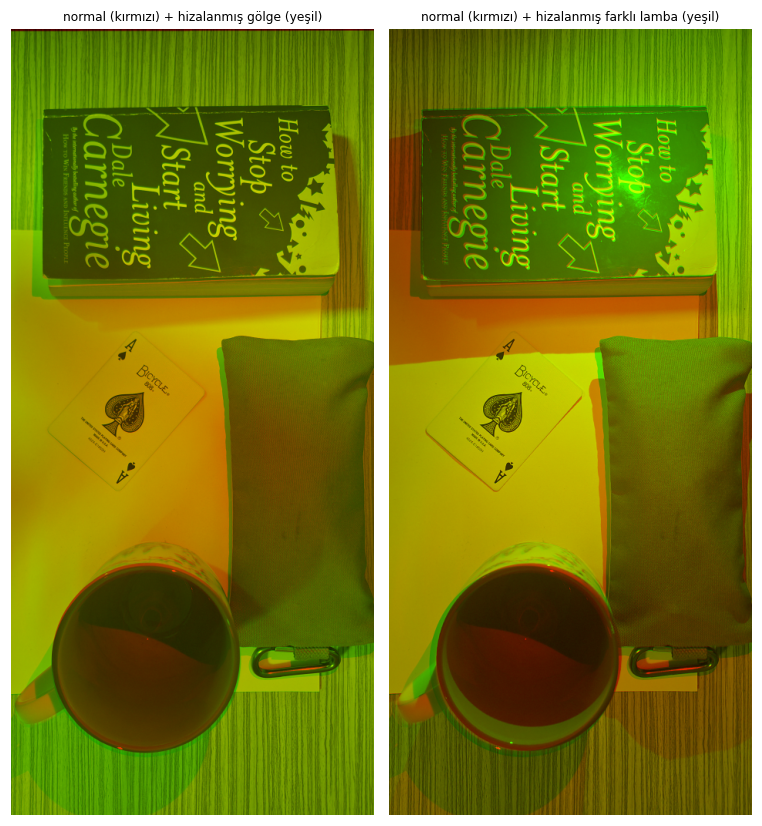

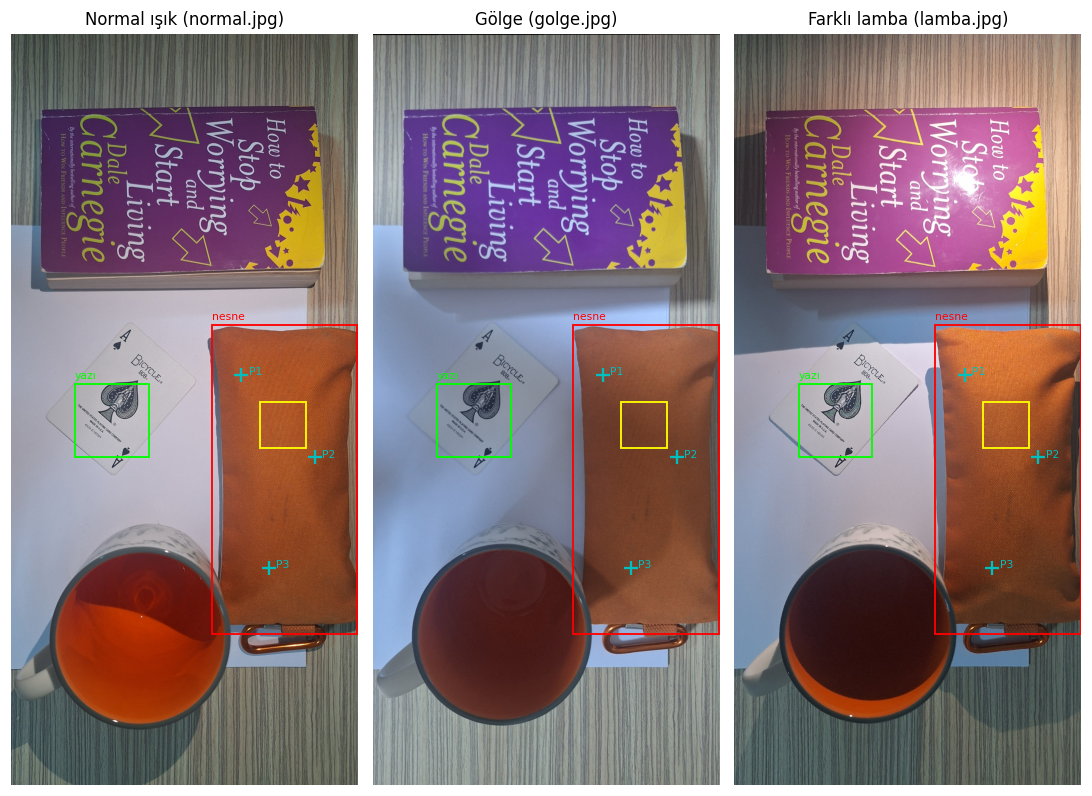

In [4]:
def orig_xy(key, x, y):
    # normal karedeki (x, y) noktasının, özgün (hizalanmamış) fotoğraftaki karşılığı
    p = cv2.perspectiveTransform(np.float32([[[x, y]]]), np.linalg.inv(HOMS[key]))[0, 0]
    return int(round(p[0])), int(round(p[1]))

def draw_rect(ax, r, color, lw=1.2, label=None):
    x, y, w, h = r
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec=color, lw=lw))
    if label:
        ax.text(x, y - 15, label, color=color, fontsize=7, va="bottom")

def norm_gray(im):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY).astype(np.float32)
    return cv2.normalize(g, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(7, 7.5))
for ax, k in zip(axes, ("golge", "lamba")):
    comp = np.dstack([norm_gray(imgs_bgr["normal"]), norm_gray(imgs_bgr[k]), np.zeros((H, W), np.uint8)])
    ax.imshow(cv2.resize(comp, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)); ax.axis("off")
    ax.set_title(f"normal (kırmızı) + hizalanmış {NAMES_TR[k].lower()} (yeşil)", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "fig0_hizalama.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10, 7.5))
for ax, k in zip(axes, FILES):
    ax.imshow(imgs_rgb[k])
    for i, (x, y) in enumerate(PIXELS, 1):
        ax.plot(x, y, "c+", ms=9, mew=1.5)
        ax.text(x + 40, y, f"P{i}", color="c", fontsize=7)
    draw_rect(ax, OBJ_BOX, "r", label="nesne")
    draw_rect(ax, OBJ_ROI, "yellow")
    draw_rect(ax, TEXT_ROI, "lime", label="yazı")
    ax.set_title(f"{NAMES_TR[k]} ({PATHS[k].name})")
    ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "fig1_fotograflar.png", bbox_inches="tight"); plt.show()

## 1. Görüntünün sayısal yapısı (H1)

**Tahmin (deneyden önce yazıldı):** Telefon fotoğrafı `H × W × 3` boyutunda, `uint8` türünde ve 0–255 aralığında olacak; OpenCV ilk kanalda R değil B verecek.
Aynı fiziksel pikselde gölgede R, G ve B'nin üçü de belirgin düşecek; sarımsı/turuncu lambada ise B kanalı R ve G'ye göre orantısız düşecek, çünkü lamba spektrumunda mavi az.

In [5]:
img = imgs_bgr["normal"]
print("img.shape =", img.shape, "-> H =", H, ", W =", W, ", C =", C)
print("img.dtype =", img.dtype, "| değer aralığı:", int(img.min()), "-", int(img.max()))
MEAS["H1"] = {"shape": list(img.shape), "dtype": str(img.dtype), "min": int(img.min()), "max": int(img.max())}

x, y = PIXELS[0]
rgb = imgs_rgb["normal"]
print(f"\nPiksel (x={x}, y={y}) -> NumPy erişimi img[y, x] (satır önce, sütun sonra)")
print("  OpenCV img[y, x]      (B, G, R) =", tuple(int(v) for v in img[y, x]))
print("  img[y, x, 2] (R kanalı)         =", int(img[y, x, 2]), "| img[y, x, 0] (B kanalı) =", int(img[y, x, 0]))
print("  cvtColor sonrası rgb[y, x] (R, G, B) =", tuple(int(v) for v in rgb[y, x]))
print("  img[..., ::-1] ile ters çevirme aynı mı?", np.array_equal(img[..., ::-1], rgb))
try:
    print("  Yanlış erişim img[x, y] =", tuple(int(v) for v in img[x, y]), "<- farklı bir piksel!")
except IndexError as e:
    print("  Yanlış erişim img[x, y] -> IndexError:", e)

img.shape = (4080, 1884, 3) -> H = 4080 , W = 1884 , C = 3
img.dtype = uint8 | değer aralığı: 0 - 255

Piksel (x=1250, y=1850) -> NumPy erişimi img[y, x] (satır önce, sütun sonra)
  OpenCV img[y, x]      (B, G, R) = (35, 74, 159)
  img[y, x, 2] (R kanalı)         = 159 | img[y, x, 0] (B kanalı) = 35
  cvtColor sonrası rgb[y, x] (R, G, B) = (159, 74, 35)
  img[..., ::-1] ile ters çevirme aynı mı? True
  Yanlış erişim img[x, y] = (116, 134, 141) <- farklı bir piksel!


In [6]:
def px_stats(key, x, y):
    r = imgs_rgb[key]; h = imgs_hsv[key]
    patch = r[max(y-NEIGH, 0):y+NEIGH+1, max(x-NEIGH, 0):x+NEIGH+1].reshape(-1, 3).mean(0)
    return orig_xy(key, x, y), tuple(int(v) for v in r[y, x]), tuple(int(round(v)) for v in patch), tuple(int(v) for v in h[y, x])

rows = []
for i, (x, y) in enumerate(PIXELS, 1):
    for k in FILES:
        oxy, v, m, hv = px_stats(k, x, y)
        rows.append({"piksel": f"P{i}", "fotoğraf": NAMES_TR[k], "x": x, "y": y, "özgün fotoğrafta (x, y)": oxy,
                     "RGB (tek piksel)": v, "RGB (5x5 ort.)": m, "HSV (tek piksel)": hv,
                     "parlaklık oranı (R+G+B)/normal": None})
px_df = pd.DataFrame(rows)
for i in range(len(PIXELS)):
    base = sum(px_df.loc[i*3, "RGB (5x5 ort.)"])
    for j in range(3):
        px_df.loc[i*3 + j, "parlaklık oranı (R+G+B)/normal"] = round(sum(px_df.loc[i*3 + j, "RGB (5x5 ort.)"]) / max(base, 1), 2)
display(px_df)
px_df.to_csv(RES / "tablo1_pikseller.csv", index=False, encoding="utf-8-sig")
MEAS["H1"]["pixels"] = px_df.astype(str).to_dict("records")

,piksel,fotoğraf,x,y,"özgün fotoğrafta (x, y)",RGB (tek piksel),RGB (5x5 ort.),HSV (tek piksel),parlaklık oranı (R+G+B)/normal
0,P1,Normal ışık,1250,1850,"(1250, 1850)","(159, 74, 35)","(165, 80, 40)","(9, 199, 159)",1.0
1,P1,Gölge,1250,1850,"(1245, 1812)","(137, 81, 66)","(132, 77, 62)","(6, 132, 137)",0.95
2,P1,Farklı lamba,1250,1850,"(1262, 1829)","(198, 108, 56)","(195, 107, 55)","(11, 183, 198)",1.25
3,P2,Normal ışık,1650,2300,"(1650, 2300)","(136, 61, 22)","(140, 66, 27)","(10, 214, 136)",1.0
4,P2,Gölge,1650,2300,"(1639, 2257)","(114, 66, 44)","(108, 60, 38)","(9, 157, 114)",0.88
5,P2,Farklı lamba,1650,2300,"(1646, 2250)","(122, 59, 26)","(124, 60, 28)","(10, 201, 122)",0.91
6,P3,Normal ışık,1400,2900,"(1400, 2900)","(122, 48, 11)","(134, 60, 25)","(10, 232, 122)",1.0
7,P3,Gölge,1400,2900,"(1391, 2849)","(108, 57, 36)","(111, 61, 39)","(9, 170, 108)",0.96
8,P3,Farklı lamba,1400,2900,"(1417, 2819)","(129, 72, 45)","(115, 57, 31)","(10, 166, 129)",0.93


**Ne gördüm, neden olabilir, nasıl kontrol ederim?**


- **Ne gördüm:** Fotoğraf `(4080, 1884, 3)`, `uint8`, 0–255. `img[y, x]` OpenCV'de `(B, G, R)` verdi; `cvtColor` ile `(R, G, B)` sırasına döndü. `img[x, y]` yazınca farklı bir piksel okundu.
  Kalemlik üzerindeki P1 (5×5 ortalama) normalde (165, 80, 40) iken gölgede (132, 77, 62) oldu: **R düştü, G neredeyse sabit kaldı, B arttı.** Lambada (195, 107, 55) oldu: üç kanal birlikte arttı.
  Bu yüzden iki tahminim de **tutmadı**: gölgede üç kanalın birlikte düşmesini, lambada B'nin orantısız düşmesini bekliyordum.
- **Neden olabilir:** EXIF'e göre otomatik pozlama ve beyaz dengesi açıktı. Gölge çekiminde kamera kazancı (süre×ISO) normalin **2,64 katına** çıktı ve karanlığı kısmen telafi etti.
  Gölgedeki yüzey artık doğrudan ışıkla değil, ortamdan/pencereden gelen mavimsi dağınık ışıkla aydınlandığı için B arttı. Lambada beyaz dengesi sıcak ışığı nötrledi: kalemliğin ortanca rengi (171, 88, 41), normaldeki (175, 87, 41) ile neredeyse aynı.
  Lambadaki parlaklık farkı ise konuma bağlı: lamba sol üstte olduğu için P1 normalin 1,25 katı, P2 ve P3 ise 0,91–0,93 katı.
- **Nasıl kontrol ederim:** Pozlama ve beyaz dengesi kilitli (Pro mod: sabit ISO, enstantane ve WB) üç fotoğrafı yeniden çekip aynı pikselleri ölçerim. Gri/beyaz kâğıdın RGB oranlarını da referans olarak kaydederim.

## 2. Sabit RGB ve HSV eşikleri (H2)

**Tahmin (deneyden önce yazıldı):** Gölgede R, G ve B birlikte düşeceği için RGB maskesinin alan oranı belirgin küçülecek; HSV maskesi ton (H) kanalı sayesinde daha az etkilenecek, ama V alt eşiğinin altına inen pikseller orada da kaybolacak.
Sıcak lambada nesnenin tonu kırmızıya kayacak ve beyaz kâğıt/masa gibi açık renkli yüzeyler sarımsılaşacağı için eşiği geçen yanlış bölgeler ortaya çıkabilir.

### 2.1 Eşiklerin türetilmesi (yalnızca normal ışık, `OBJ_ROI`)
Aşağıdaki hücre yalnızca **öneri** üretir (yüzde 2–98 aralığı + pay). Önerilen değerler bir kez parametre hücresine elle yazılmış ve dondurulmuştur;
sonraki hücreler yalnızca dondurulmuş değerleri kullanır.

In [7]:
x0, y0, w0, h0 = OBJ_ROI
roi_rgb = imgs_rgb["normal"][y0:y0+h0, x0:x0+w0].reshape(-1, 3).astype(int)
roi_hsv = imgs_hsv["normal"][y0:y0+h0, x0:x0+w0].reshape(-1, 3).astype(int)
p_rgb = np.percentile(roi_rgb, [2, 50, 98], axis=0)
p_hsv = np.percentile(roi_hsv, [2, 50, 98], axis=0)
print(f"OBJ_ROI = {OBJ_ROI}  ({roi_rgb.shape[0]} piksel)")
print("RGB yüzde 2 / 50 / 98:", p_rgb.round().astype(int).tolist())
print("HSV yüzde 2 / 50 / 98:", p_hsv.round().astype(int).tolist())
sug_rgb_lo = np.clip(p_rgb[0] - 25, 0, 255).astype(int); sug_rgb_hi = np.clip(p_rgb[2] + 25, 0, 255).astype(int)
sug_hsv_lo = [int(max(p_hsv[0, 0] - 5, 0)), int(max(p_hsv[0, 1] - 40, 0)), int(max(p_hsv[0, 2] - 60, 0))]
sug_hsv_hi = [int(min(p_hsv[2, 0] + 5, 179)), 255, 255]
print("\nÖnerilen RGB:", tuple(sug_rgb_lo.tolist()), "-", tuple(sug_rgb_hi.tolist()))
print("Önerilen HSV:", tuple(sug_hsv_lo), "-", tuple(sug_hsv_hi))
print("\nDONDURULMUŞ (kullanılan) RGB:", RGB_LO, "-", RGB_HI)
print("DONDURULMUŞ (kullanılan) HSV:", HSV_LO, "-", HSV_HI)
MEAS["H2"] = {"OBJ_ROI": OBJ_ROI, "OBJ_BOX": OBJ_BOX, "RGB_LO": RGB_LO, "RGB_HI": RGB_HI, "HSV_LO": HSV_LO, "HSV_HI": HSV_HI,
              "roi_rgb_p2_p50_p98": p_rgb.round(1).tolist(), "roi_hsv_p2_p50_p98": p_hsv.round(1).tolist()}

OBJ_ROI = (1350, 2000, 250, 250)  (62500 piksel)
RGB yüzde 2 / 50 / 98: [[141, 53, 6], [175, 87, 41], [206, 118, 70]]
HSV yüzde 2 / 50 / 98: [[10, 167, 141], [10, 195, 175], [11, 244, 206]]

Önerilen RGB: (116, 28, 0) - (231, 143, 95)
Önerilen HSV: (5, 127, 81) - (16, 255, 255)

DONDURULMUŞ (kullanılan) RGB: (115, 30, 0) - (230, 145, 95)
DONDURULMUŞ (kullanılan) HSV: (5, 125, 80) - (16, 255, 255)


### 2.2 Aynı eşiklerin üç fotoğrafa uygulanması — 6 maske

In [8]:
def mask_rgb(rgb_img):
    return cv2.inRange(rgb_img, np.array(RGB_LO, np.uint8), np.array(RGB_HI, np.uint8))

def mask_hsv(hsv_img):
    lo, hi = np.array(HSV_LO, np.uint8), np.array(HSV_HI, np.uint8)
    if HSV_LO[0] <= HSV_HI[0]:
        return cv2.inRange(hsv_img, lo, hi)
    # kırmızı gibi H=0/179 sınırını kesen tonlar için iki aralığın birleşimi
    m1 = cv2.inRange(hsv_img, lo, np.array([179, HSV_HI[1], HSV_HI[2]], np.uint8))
    m2 = cv2.inRange(hsv_img, np.array([0, HSV_LO[1], HSV_LO[2]], np.uint8), hi)
    return cv2.bitwise_or(m1, m2)

masks, mrows = {}, []
bx, by, bw, bh = OBJ_BOX
box = np.zeros((H, W), bool); box[by:by+bh, bx:bx+bw] = True
rx, ry, rw, rh = OBJ_ROI
roi = np.zeros((H, W), bool); roi[ry:ry+rh, rx:rx+rw] = True
AREA = int(COMMON.sum())
for k in FILES:
    for space, m in (("RGB", mask_rgb(imgs_rgb[k])), ("HSV", mask_hsv(imgs_hsv[k]))):
        m[~COMMON] = 0                      # yalnızca üç fotoğrafın ortak görüş alanı
        masks[(space, k)] = m
        sel = m > 0; n = int(sel.sum())
        mrows.append({"fotoğraf": NAMES_TR[k], "uzay": space, "seçilen piksel": n,
                      "alan oranı (%)": round(100 * n / AREA, 3),
                      "OBJ_ROI içinde seçilen (%)": round(100 * sel[roi].mean(), 1),
                      "seçilenlerin nesne kutusu dışındaki payı (%)": round(100 * (sel & ~box).sum() / max(n, 1), 1)})
mask_df = pd.DataFrame(mrows)
display(mask_df)
mask_df.to_csv(RES / "tablo2_maskeler.csv", index=False, encoding="utf-8-sig")
MEAS["H2"]["masks"] = mask_df.to_dict("records")
print("Not: alan oranı bir doğruluk ölçütü DEĞİLDİR; yalnızca eşiği geçen piksellerin görüntüye oranıdır.")

# Nesne bölgesinin (OBJ_ROI) üç fotoğraftaki ortanca değerleri: maskenin neden değiştiğini açıklamak için
srows = []
for k in FILES:
    r = imgs_rgb[k][ry:ry+rh, rx:rx+rw].reshape(-1, 3)
    h = imgs_hsv[k][ry:ry+rh, rx:rx+rw].reshape(-1, 3)
    mr, mh = np.median(r, 0).astype(int), np.median(h, 0).astype(int)
    srows.append({"fotoğraf": NAMES_TR[k], "R": mr[0], "G": mr[1], "B": mr[2], "H": mh[0], "S": mh[1], "V": mh[2]})
roi_df = pd.DataFrame(srows)
print("\nOBJ_ROI ortanca değerleri:"); display(roi_df)
roi_df.to_csv(RES / "tablo2b_nesne_ortanca.csv", index=False, encoding="utf-8-sig")
MEAS["H2"]["roi_median"] = roi_df.to_dict("records")
MEAS["H2"]["common_area_px"] = AREA

,fotoğraf,uzay,seçilen piksel,alan oranı (%),OBJ_ROI içinde seçilen (%),seçilenlerin nesne kutusu dışındaki payı (%)
0,Normal ışık,RGB,1575293,20.541,100.0,32.6
1,Normal ışık,HSV,1593326,20.777,100.0,28.1
2,Gölge,RGB,725444,9.460,57.8,2.4
3,Gölge,HSV,1102782,14.380,100.0,3.9
4,Farklı lamba,RGB,878519,11.456,99.8,21.7
5,Farklı lamba,HSV,1153656,15.043,100.0,8.4


Not: alan oranı bir doğruluk ölçütü DEĞİLDİR; yalnızca eşiği geçen piksellerin görüntüye oranıdır.

OBJ_ROI ortanca değerleri:


,fotoğraf,R,G,B,H,S,V
0,Normal ışık,175,87,41,10,195,175
1,Gölge,117,65,43,9,162,117
2,Farklı lamba,171,88,41,11,194,171


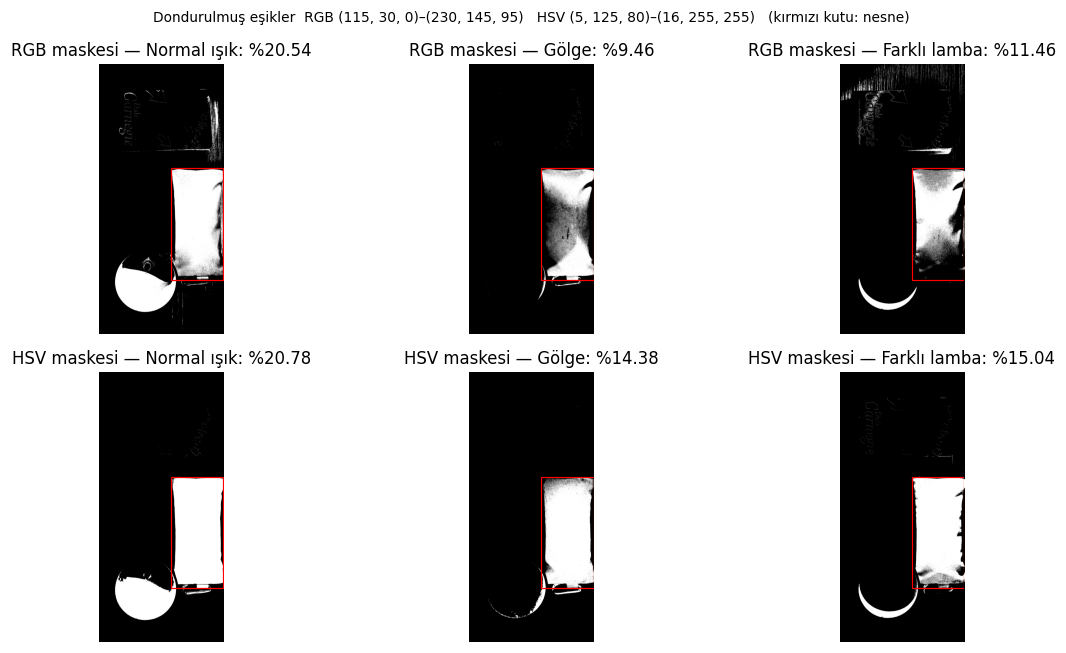

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for i, space in enumerate(("RGB", "HSV")):
    for j, k in enumerate(FILES):
        ax = axes[i, j]
        ax.imshow(masks[(space, k)], cmap="gray", vmin=0, vmax=255, interpolation="antialiased")
        draw_rect(ax, OBJ_BOX, "r", lw=0.8)
        ratio = mask_df[(mask_df["uzay"] == space) & (mask_df["fotoğraf"] == NAMES_TR[k])]["alan oranı (%)"].iloc[0]
        ax.set_title(f"{space} maskesi — {NAMES_TR[k]}: %{ratio:.2f}")
        ax.axis("off")
plt.suptitle(f"Dondurulmuş eşikler  RGB {RGB_LO}–{RGB_HI}   HSV {HSV_LO}–{HSV_HI}   (kırmızı kutu: nesne)", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "fig2_maskeler.png", bbox_inches="tight"); plt.show()

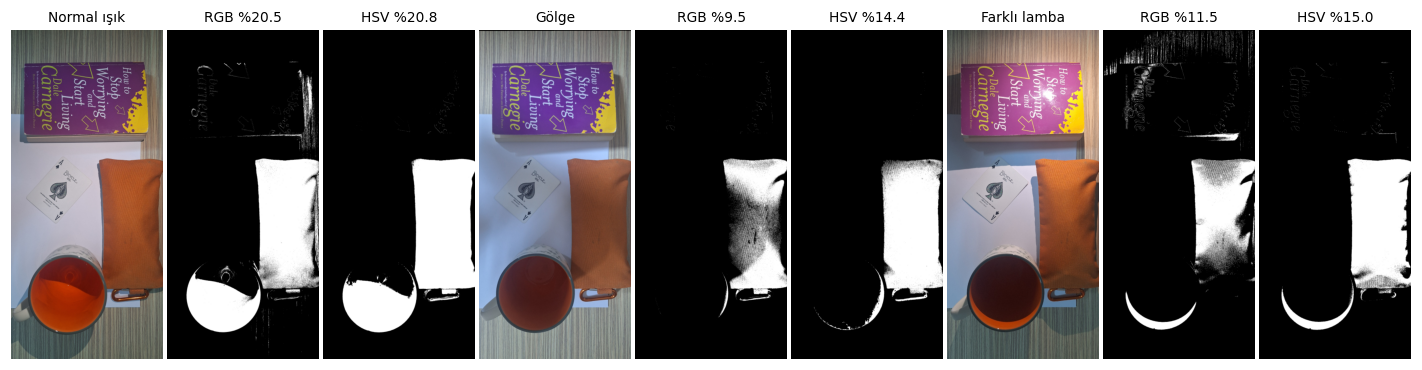

In [10]:
# Rapor için kompakt şekil: her koşulda özgün (hizalanmış) fotoğraf + RGB maskesi + HSV maskesi
fig, axes = plt.subplots(1, 9, figsize=(13, 3.9))
for g, k in enumerate(FILES):
    small = lambda a: cv2.resize(a, None, fx=0.2, fy=0.2, interpolation=cv2.INTER_AREA)
    panels = [(imgs_rgb[k], NAMES_TR[k], None)]
    for space in ("RGB", "HSV"):
        ratio = mask_df[(mask_df["uzay"] == space) & (mask_df["fotoğraf"] == NAMES_TR[k])]["alan oranı (%)"].iloc[0]
        panels.append((masks[(space, k)], f"{space} %{ratio:.1f}", "gray"))
    for j, (a, title, cmap) in enumerate(panels):
        ax = axes[3 * g + j]
        ax.imshow(small(a), cmap=cmap, vmin=0, vmax=255); ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout(w_pad=0.3); plt.savefig(OUT / "fig5_rapor_foto_maske.png", bbox_inches="tight", dpi=200); plt.show()

### 2.3 Seçilen piksellerin sahnedeki dağılımı
Eşiği geçen piksellerin hangi bölgeden geldiğini görmek için sahneyi elle çizilmiş dikdörtgen bölgelere ayırdım (`REGIONS`, normal karede).
Her hücre, o maskede seçilen piksellerin yüzde kaçının o bölgede olduğunu gösterir. Bu da bir doğruluk ölçütü değildir; yalnızca "maske neyi seçti?" sorusunu yanıtlar.

In [11]:
reg_masks = {}
for name, (x, y, w, h) in REGIONS.items():
    r = np.zeros((H, W), bool); r[y:y+h, x:x+w] = True
    reg_masks[name] = r & COMMON
used = np.zeros((H, W), bool)
for r in reg_masks.values():
    used |= r
reg_masks["diğer"] = COMMON & ~used
rrows = []
for k in FILES:
    for space in ("RGB", "HSV"):
        sel = masks[(space, k)] > 0; n = max(int(sel.sum()), 1)
        row = {"fotoğraf": NAMES_TR[k], "uzay": space}
        row.update({name: round(100 * (sel & r).sum() / n, 1) for name, r in reg_masks.items()})
        rrows.append(row)
reg_df = pd.DataFrame(rrows)
display(reg_df)
reg_df.to_csv(RES / "tablo2c_bolge_dagilimi.csv", index=False, encoding="utf-8-sig")
MEAS["H2"]["regions"] = {"REGIONS": REGIONS, "table": reg_df.to_dict("records")}

# Seçilen ahşap/kupa piksellerinin ortanca rengi (neden seçildiklerini açıklamak için)
for k in FILES:
    for name in ("üst ahşap", "kupa (çay)"):
        sel = (masks[("RGB", k)] > 0) & reg_masks[name]
        if sel.sum() > 100:
            med_rgb = np.median(imgs_rgb[k][sel], 0).astype(int); med_hsv = np.median(imgs_hsv[k][sel], 0).astype(int)
            print(f"{NAMES_TR[k]:12s} | RGB maskesinin seçtiği {name:10s}: {int(sel.sum()):7d} px, ortanca RGB {tuple(med_rgb.tolist())}, HSV {tuple(med_hsv.tolist())}")
# Aynı ahşap bölgesinin üç fotoğraftaki ortanca rengi
x, y, w, h = REGIONS["üst ahşap"]
for k in FILES:
    patch = imgs_rgb[k][y:y+h, x:x+w].reshape(-1, 3); hp = imgs_hsv[k][y:y+h, x:x+w].reshape(-1, 3)
    print(f"{NAMES_TR[k]:12s} | üst ahşap bölgesinin tümü: ortanca RGB {tuple(np.median(patch, 0).astype(int).tolist())}, HSV {tuple(np.median(hp, 0).astype(int).tolist())}")

,fotoğraf,uzay,kalemlik,kupa (çay),kitap,üst ahşap,diğer
0,Normal ışık,RGB,67.4,26.9,1.3,0.0,4.4
1,Normal ışık,HSV,71.9,26.2,0.1,0.0,1.8
2,Gölge,RGB,97.6,0.1,0.2,0.0,2.1
3,Gölge,HSV,96.1,1.7,0.0,0.0,2.2
4,Farklı lamba,RGB,78.3,8.5,6.9,4.7,1.7
5,Farklı lamba,HSV,91.6,6.9,0.5,0.0,1.0


Normal ışık  | RGB maskesinin seçtiği kupa (çay):  423441 px, ortanca RGB (160, 44, 4), HSV (7, 249, 160)
Gölge        | RGB maskesinin seçtiği kupa (çay):     783 px, ortanca RGB (117, 63, 46), HSV (7, 155, 117)
Farklı lamba | RGB maskesinin seçtiği üst ahşap :   40885 px, ortanca RGB (124, 102, 92), HSV (10, 71, 124)
Farklı lamba | RGB maskesinin seçtiği kupa (çay):   74285 px, ortanca RGB (170, 62, 13), HSV (10, 235, 170)
Normal ışık  | üst ahşap bölgesinin tümü: ortanca RGB (90, 94, 86), HSV (42, 23, 94)
Gölge        | üst ahşap bölgesinin tümü: ortanca RGB (127, 129, 127), HSV (63, 10, 130)
Farklı lamba | üst ahşap bölgesinin tümü: ortanca RGB (150, 125, 110), HSV (12, 61, 150)


**Ne gördüm, neden olabilir, nasıl kontrol ederim?**


- **Ne gördüm:** Kalemlikten türetilen eşikler normal ışıkta kalemliği tam seçti (OBJ_ROI'de %100), ama seçilen piksellerin **%27'si çaydan** geldi; kupadaki turuncu çay, kalemlikle aynı renkte.
  Gölgede RGB maskesi %20,5'ten %9,5'e düştü ve kalemliğin ortasındaki referans bölgenin yalnızca %57,8'ini seçti. HSV maskesi %14,4'te kaldı ve aynı bölgenin %100'ünü seçti.
  Lambada RGB maskesi üst ahşaptan 40 885 piksel ve kitaptan da piksel seçti (seçimlerin %4,7'si ve %6,9'u). HSV maskesi ahşaptan hiç piksel seçmedi.
- **Neden olabilir:** Gölgede kalemliğin ortanca değerleri (175, 87, 41) → (117, 65, 43) oldu; R alt eşik 115'e dayandı. HSV'de ton neredeyse sabit kaldı (H 10 → 9), ama doygunluk 195 → 162'ye ve P1'de 132'ye indi.
  Bu değer S alt eşiği 125'e çok yakın; yani **HSV'yi bu gölgede yalnızca bıraktığım pay kurtardı**, HSV ışık değişimine karşı tamamen dayanıklı değil.
  Lambada griye yakın ahşap (H 42, S 23) sıcak ışıkla turuncumsuya döndü (H 12, S 61). RGB kutusu her kanalı ayrı sınırladığı ve doygunluğu denetlemediği için soluk turuncu ahşabın bir kısmı (124, 102, 92) kutunun içine düştü. HSV'deki S ≥ 125 koşulu bu solukluğu reddetti.
  Not: alan oranı bir doğruluk ölçütü değildir. HSV'nin gölgede düşüşünün büyük kısmı kalemlikten değil, karanlıkta seçilmeyen çaydan geliyor.
- **Nasıl kontrol ederim:** Maskeyi yalnızca kalemlik kutusunda ölçerim (5. bölümdeki tabloda). Çayı ayırmak için renk dışında şekil/doku ölçütü (bağlı bileşenin en–boy oranı, doluluk) eklerim. Gölge için S ve V alt eşiklerini değiştirip HSV kapsamının hangi değerde çöktüğünü ölçerim.

## 3. Parlaklık kaydırması ve gama (H3)

Dönüşümler normal ışıklı fotoğrafa (RGB, üç kanal birlikte) **float32** üzerinde uygulanır, `[0, 255]` aralığına kırpılır, sonra yuvarlanıp `uint8`'e çevrilir.
Bu ödevde γ formüldeki üstür: `J = 255 · (I / 255)^γ`.

**Tahmin (deneyden önce yazıldı):** b = +40 ortalamayı yaklaşık 40 artıracak ama 215'ten parlak pikseller 255'te kırpılacağı için ölçülen artış 40'tan az olacak; beyaz kâğıt en çok kırpılan bölge olacak.
γ = 0,5 görüntüyü aydınlatacak (koyu tonları en çok açar), γ = 2,0 karartacak; ortalamanın kabaca `255·(m/255)^γ` olacağını bekliyorum.

In [12]:
def brightness(img, b):
    J = np.clip(img.astype(np.float32) + b, 0, 255)
    return np.rint(J).astype(np.uint8)

def gamma(img, g):
    J = 255.0 * (img.astype(np.float32) / 255.0) ** g
    return np.rint(np.clip(J, 0, 255)).astype(np.uint8)

# formül kontrolü: tek değerli piksel
for g in GAMMAS:
    print(f"64 -> gamma(γ={g}) = {255 * (64 / 255) ** g:.1f}")
print("200 -> brightness(+40) =", int(brightness(np.array([[200]], np.uint8), B_SHIFT)[0, 0]),
      "| 230 -> brightness(+40) =", int(brightness(np.array([[230]], np.uint8), B_SHIFT)[0, 0]), "(kırpıldı)")

I = imgs_rgb["normal"]
m = float(I.mean())
pred = {"b=+40": m + B_SHIFT}
pred.update({f"γ={g}": 255 * (m / 255) ** g for g in GAMMAS})
print(f"\nÖzgün ortalama m = {m:.2f}")
print("ÖN TAHMİN (dönüşüm uygulanmadan önce, yalnızca m'den hesaplanır):")
for k, v in pred.items():
    print(f"  {k:7s}: {v:.2f}")

64 -> gamma(γ=0.5) = 127.7
64 -> gamma(γ=2.0) = 16.1
200 -> brightness(+40) = 240 | 230 -> brightness(+40) = 255 (kırpıldı)

Özgün ortalama m = 111.32
ÖN TAHMİN (dönüşüm uygulanmadan önce, yalnızca m'den hesaplanır):
  b=+40  : 151.32
  γ=0.5  : 168.49
  γ=2.0  : 48.60


In [13]:
outs = {"özgün": I, f"b=+{B_SHIFT}": brightness(I, B_SHIFT)}
outs.update({f"γ={g}": gamma(I, g) for g in GAMMAS})
clip_frac = float((I.astype(int) + B_SHIFT > 255).mean())
exact_b = float(np.minimum(I.astype(np.float32) + B_SHIFT, 255).mean())

rows = []
for name, J in outs.items():
    key = "b=+40" if name.startswith("b=") else name
    rows.append({"dönüşüm": name, "ön tahmin (ortalama)": round(pred.get(key, m), 2), "ölçülen ortalama": round(float(J.mean()), 2),
                 "fark (ölçülen − tahmin)": round(float(J.mean()) - pred.get(key, m), 2),
                 "255'teki değer (%)": round(100 * float((J == 255).mean()), 2), "0'daki değer (%)": round(100 * float((J == 0).mean()), 2),
                 "std": round(float(J.std()), 2)})
gam_df = pd.DataFrame(rows)
display(gam_df)
gam_df.to_csv(RES / "tablo3_parlaklik_gama.csv", index=False, encoding="utf-8-sig")
print(f"b=+{B_SHIFT}: I > {255 - B_SHIFT} olan (kırpılan) kanal değerlerinin oranı = %{100 * clip_frac:.2f}")
print(f"Kırpmayı hesaba katan beklenen ortalama mean(min(I+{B_SHIFT}, 255)) = {exact_b:.2f}")

# γ için ön tahminin neden tutmadığını kontrol: dağılım üzerinden beklenen değer
for g in GAMMAS:
    e = float((255 * (I.astype(np.float64) / 255) ** g).mean())
    print(f"γ={g}: 255·(m/255)^γ = {pred[f'γ={g}']:.2f}  vs  mean(255·(I/255)^γ) = {e:.2f}  (Jensen eşitsizliği)")
MEAS["H3"] = {"mean_original": m, "prediction": pred, "table": gam_df.to_dict("records"),
              "clip_fraction_b40": clip_frac, "expected_mean_b40_with_clip": exact_b}

,dönüşüm,ön tahmin (ortalama),ölçülen ortalama,fark (ölçülen − tahmin),255'teki değer (%),0'daki değer (%),std
0,özgün,111.32,111.32,0.00,0.01,0.34,54.47
1,b=+40,151.32,151.30,-0.03,0.46,0.00,54.42
2,γ=0.5,168.49,162.22,-6.26,0.01,0.34,45.46
3,γ=2.0,48.60,60.22,11.62,0.01,1.92,50.30


b=+40: I > 215 olan (kırpılan) kanal değerlerinin oranı = %0.39
Kırpmayı hesaba katan beklenen ortalama mean(min(I+40, 255)) = 151.30
γ=0.5: 255·(m/255)^γ = 168.49  vs  mean(255·(I/255)^γ) = 162.24  (Jensen eşitsizliği)


γ=2.0: 255·(m/255)^γ = 48.60  vs  mean(255·(I/255)^γ) = 60.24  (Jensen eşitsizliği)


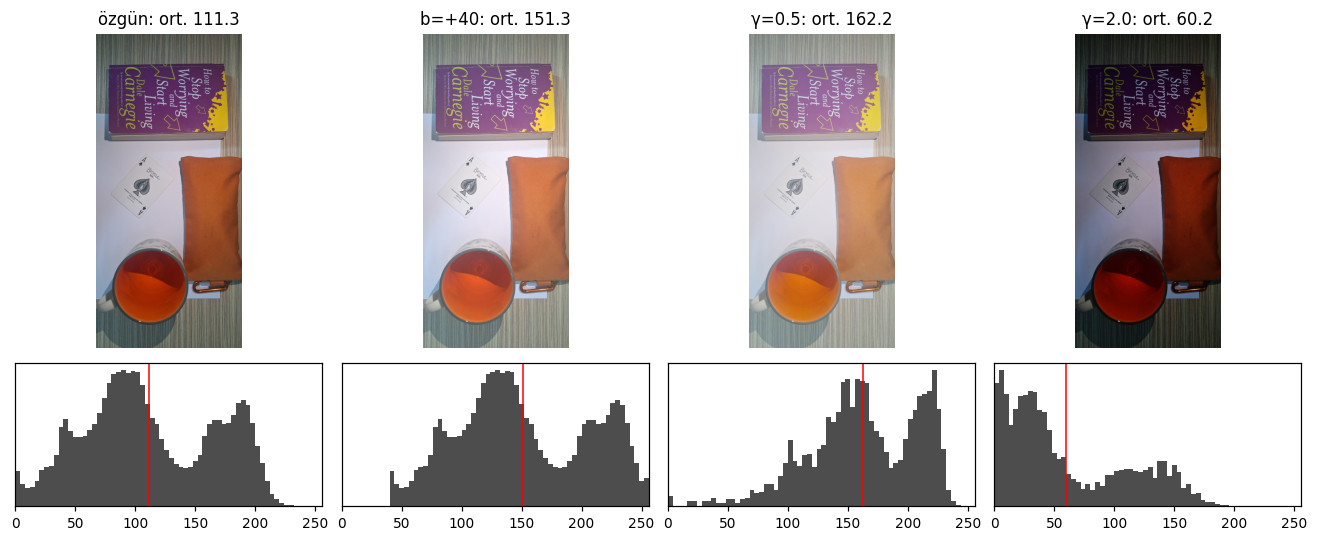

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5), gridspec_kw={"height_ratios": [2.2, 1]})
for j, (name, J) in enumerate(outs.items()):
    axes[0, j].imshow(J); axes[0, j].set_title(f"{name}: ort. {J.mean():.1f}"); axes[0, j].axis("off")
    axes[1, j].hist(J.ravel(), bins=64, range=(0, 256), color="0.3")
    axes[1, j].set_xlim(0, 256); axes[1, j].set_yticks([])
    axes[1, j].axvline(J.mean(), color="r", lw=1)
plt.tight_layout(); plt.savefig(OUT / "fig3_parlaklik_gama.png", bbox_inches="tight"); plt.show()

**Ne gördüm, neden olabilir, nasıl kontrol ederim?**


- **Ne gördüm:** Ortalama 111,32 iken b = +40 sonrası **151,30** oldu, yani tam +39,98. 215'i aşıp 255'te kırpılan kanal değerlerinin oranı yalnızca %0,39. Kırpılmayı ve beyaz kâğıdın en çok etkileneceğini öngören tahminim **tutmadı**.
  Gamada yön doğruydu (γ = 0,5 açtı, γ = 2,0 kararttı), ama ortalamaya formülü uygulayarak yaptığım tahmin **tutmadı**: γ = 0,5 için 168,5 bekledim, 162,2 ölçtüm; γ = 2,0 için 48,6 bekledim, 60,2 ölçtüm.
  Tek değer kontrolü beklendiği gibi: 64 → 127,7 (γ = 0,5) ve 64 → 16,1 (γ = 2,0).
- **Neden olabilir:** Otomatik pozlama, beyaz kâğıdı bile ~190 civarında tuttu (kartta P99 = 217). 215'i aşan değer çok az olduğu için +40 kaydırması neredeyse hiç kırpılmadı.
  Gama doğrusal olmayan bir dönüşüm: ortalamanın gaması, gamanın ortalamasına eşit değildir (Jensen eşitsizliği). İçbükey γ = 0,5'te ortalama tahminin altında, dışbükey γ = 2,0'da üstünde kalır.
- **Nasıl kontrol ederim:** Tahmini piksel dağılımı üzerinden yaptım: `mean(min(I+40, 255)) = 151,30` ve `mean(255·(I/255)^γ) = 162,24 / 60,24` ölçümle örtüştü. Kırpmayı görmek için daha parlak (aşırı pozlanmış) bir fotoğrafta aynı deneyi tekrarlarım.

## 4. 1/4 küçültmenin etkisi (H4)

**Tahmin (deneyden önce yazıldı):** Küçük puntolu harflerin yüksekliği 1/4 küçültmede 2–3 piksele inecek ve yazı okunamayacak.
`INTER_NEAREST` her 4×4 bloktan tek pikseli alacağı için harf çizgilerini koparıp düzensiz/sahte desen üretecek; `INTER_AREA` blok ortalaması aldığı için yazıyı griye çevirip bulanıklaştıracak ama sahte desen üretmeyecek.
En yakın komşuyla geri büyütmek kaybolan ayrıntıyı geri getirmeyecek, yalnızca blokları büyütecek.

In [15]:
tx, ty, tw, th = TEXT_ROI
tw, th = tw - tw % FACTOR, th - th % FACTOR          # 4'ün katı olsun ki geri büyütme tam özgün boyuta dönsün
crop = imgs_rgb["normal"][ty:ty+th, tx:tx+tw].copy()
small = {m_: cv2.resize(crop, (tw // FACTOR, th // FACTOR), interpolation=getattr(cv2, m_))
         for m_ in ("INTER_NEAREST", "INTER_AREA")}
up = {m_: cv2.resize(s, (tw, th), interpolation=cv2.INTER_NEAREST) for m_, s in small.items()}       # yalnızca gösterim için
up_cubic = cv2.resize(small["INTER_AREA"], (tw, th), interpolation=cv2.INTER_CUBIC)                  # ek kontrol
print("kesit:", crop.shape, "-> küçük:", small["INTER_AREA"].shape, "-> geri büyütülmüş:", up["INTER_AREA"].shape)

gray = lambda a: cv2.cvtColor(a, cv2.COLOR_RGB2GRAY).astype(np.float64)
g0 = gray(crop)

# Harf yüksekliği tahmini: Otsu ile koyu mürekkep, bağlı bileşenlerin ortanca yüksekliği
_, bw = cv2.threshold(g0.astype(np.uint8), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
n_cc, _, st, _ = cv2.connectedComponentsWithStats(bw, connectivity=8)
hs = st[1:, cv2.CC_STAT_HEIGHT]; ar = st[1:, cv2.CC_STAT_AREA]
keep = (ar >= 8) & (hs >= 3) & (hs < th / 3)
letter_h = float(np.median(hs[keep])) if keep.any() else float("nan")
print(f"Bağlı bileşen sayısı: {keep.sum()} | ortanca harf/çizgi yüksekliği ≈ {letter_h:.1f} px -> 1/{FACTOR} sonrası ≈ {letter_h / FACTOR:.1f} px")

# Kaybolan bilgi: yeni Nyquist sınırının (1/(2·FACTOR) devir/piksel) üstündeki spektral enerji payı
F = np.abs(np.fft.fftshift(np.fft.fft2(g0 - g0.mean()))) ** 2
fy = np.fft.fftshift(np.fft.fftfreq(th))[:, None]; fx = np.fft.fftshift(np.fft.fftfreq(tw))[None, :]
hf = (np.abs(fx) > 0.5 / FACTOR) | (np.abs(fy) > 0.5 / FACTOR)
hf_frac = float(F[hf].sum() / F.sum())
print(f"Özgün kesitte |f| > {0.5 / FACTOR:.3f} devir/piksel olan enerji payı = %{100 * hf_frac:.1f}  (1/{FACTOR} örneklemede temsil edilemez)")

def psnr(a, b):
    mse = float(((a - b) ** 2).mean()); return mse, 10 * np.log10(255 ** 2 / mse) if mse > 0 else float("inf")

def sharp(a):
    return float(cv2.Laplacian(a, cv2.CV_64F).var())

rows = [{"görüntü": "özgün kesit", "boyut": f"{tw}x{th}", "MSE": 0.0, "PSNR (dB)": float("inf"),
         "mürekkep koyuluğu P1": round(float(np.percentile(g0, 1)), 1), "kâğıt P99": round(float(np.percentile(g0, 99)), 1),
         "kontrast (std)": round(float(g0.std()), 1), "Laplace varyansı": round(sharp(g0), 1)}]
for name, a in (("NEAREST küçük", small["INTER_NEAREST"]), ("AREA küçük", small["INTER_AREA"]),
                ("NEAREST ↑ en yakın komşu", up["INTER_NEAREST"]), ("AREA ↑ en yakın komşu", up["INTER_AREA"]),
                ("AREA ↑ bikübik (ek)", up_cubic)):
    g = gray(a)
    mse, p = psnr(g0, g) if g.shape == g0.shape else (float("nan"), float("nan"))
    rows.append({"görüntü": name, "boyut": f"{a.shape[1]}x{a.shape[0]}", "MSE": round(mse, 1), "PSNR (dB)": round(p, 2),
                 "mürekkep koyuluğu P1": round(float(np.percentile(g, 1)), 1), "kâğıt P99": round(float(np.percentile(g, 99)), 1),
                 "kontrast (std)": round(float(g.std()), 1), "Laplace varyansı": round(sharp(g), 1)})
ds_df = pd.DataFrame(rows)
display(ds_df)
ds_df.to_csv(RES / "tablo4_kucultme.csv", index=False, encoding="utf-8-sig")
nn_vs_area = float(np.abs(gray(small["INTER_NEAREST"]) - gray(small["INTER_AREA"])).mean())
print(f"Küçük NEAREST ile küçük AREA arasındaki ortalama mutlak fark = {nn_vs_area:.1f} gri düzey")
MEAS["H4"] = {"TEXT_ROI": [tx, ty, tw, th], "factor": FACTOR, "letter_height_px": letter_h,
              "letter_height_after_px": letter_h / FACTOR, "hf_energy_fraction": hf_frac,
              "nearest_vs_area_mad": nn_vs_area, "table": ds_df.to_dict("records")}

kesit: (400, 400, 3) -> küçük: (100, 100, 3) -> geri büyütülmüş: (400, 400, 3)
Bağlı bileşen sayısı: 48 | ortanca harf/çizgi yüksekliği ≈ 12.0 px -> 1/4 sonrası ≈ 3.0 px
Özgün kesitte |f| > 0.125 devir/piksel olan enerji payı = %21.6  (1/4 örneklemede temsil edilemez)


,görüntü,boyut,MSE,PSNR (dB),mürekkep koyuluğu P1,kâğıt P99,kontrast (std),Laplace varyansı
0,özgün kesit,400x400,0.0,inf,31.0,217.0,48.6,2055.4
1,NEAREST küçük,100x100,NaN,NaN,32.0,218.0,48.7,23106.5
2,AREA küçük,100x100,NaN,NaN,49.0,200.0,41.4,6926.6
3,NEAREST ↑ en yakın komşu,400x400,1607.5,16.07,32.0,218.0,48.7,2876.7
4,AREA ↑ en yakın komşu,400x400,650.2,20.00,49.0,200.0,41.4,974.8
5,AREA ↑ bikübik (ek),400x400,584.9,20.46,49.0,203.0,40.5,46.6


Küçük NEAREST ile küçük AREA arasındaki ortalama mutlak fark = 15.4 gri düzey


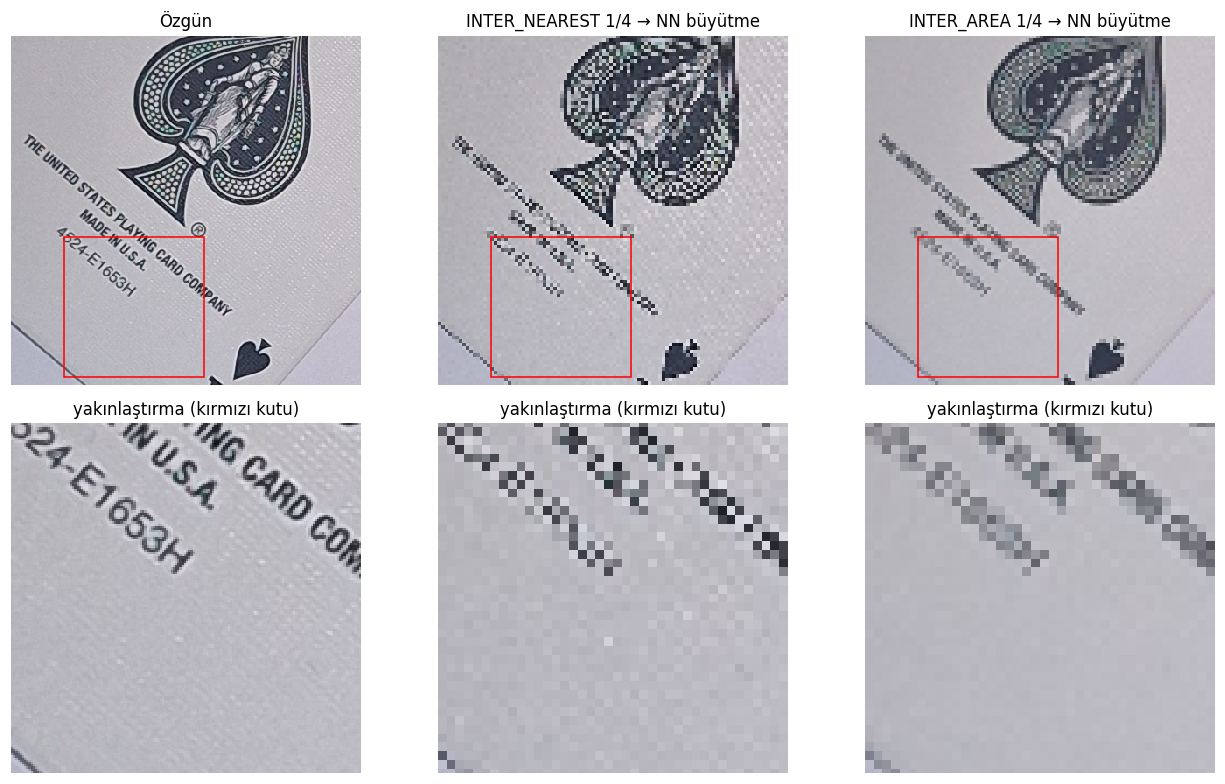

In [16]:
# Yan yana: aynı kesit (üst satır) ve ortasından 4 kat yakınlaştırılmış alt kesit (alt satır)
zx, zy, zw, zh = TEXT_ZOOM
panels = [("Özgün", crop), (f"INTER_NEAREST 1/{FACTOR} → NN büyütme", up["INTER_NEAREST"]),
          (f"INTER_AREA 1/{FACTOR} → NN büyütme", up["INTER_AREA"])]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.2))
for j, (name, a) in enumerate(panels):
    axes[0, j].imshow(a, interpolation="nearest"); axes[0, j].set_title(name); axes[0, j].axis("off")
    axes[0, j].add_patch(plt.Rectangle((zx, zy), zw, zh, fill=False, ec="r", lw=1))
    axes[1, j].imshow(a[zy:zy+zh, zx:zx+zw], interpolation="nearest"); axes[1, j].set_title("yakınlaştırma (kırmızı kutu)"); axes[1, j].axis("off")
plt.tight_layout(); plt.savefig(OUT / "fig4_kucultme.png", bbox_inches="tight"); plt.show()

**Ne gördüm, neden olabilir, nasıl kontrol ederim?**


- **Ne gördüm:** Karttaki harflerin ortanca yüksekliği ≈ 12 px; 1/4 küçültmede ≈ 3 px'e indi ve iki yöntemde de "THE UNITED STATES PLAYING CARD COMPANY" okunamaz oldu. Tahminim **tuttu**.
  `INTER_NEAREST` kartın ince keten dokusunu çapraz damalı **sahte bir desene** çevirdi, harfleri kopuk noktalara böldü ve kontrastı korudu (std 48,7). Bu küçük görüntünün Laplace varyansı AREA'nınkinin 3,3 katı: bu keskinlik değil, örtüşmeden (aliasing) gelen sahte yüksek frekans.
  `INTER_AREA` dokuyu tamamen yok etti ve yazıyı griye çevirdi: mürekkep P1 (en koyu %1) 31 → 49, kâğıt P99 (en açık %1) 217 → 200, std 48,6 → 41,4. Sahte desen üretmedi.
  İki küçük görüntü arasındaki ortalama fark 15,4 gri düzey.
- **Neden olabilir:** 1/4 örneklemede temsil edilebilen en yüksek frekans 0,125 devir/pikseldir; özgün kesitteki enerjinin **%21,6'sı** bu sınırın üstünde.
  NEAREST bu frekansları süzmeden her 4×4 bloktan tek piksel aldığı için onları düşük frekanslı sahte desenlere katlar (örtüşme). AREA bloğu ortalayarak bu frekansları önce siler.
- **Büyütme neden geri getirmedi:** 160 000 pikselden 10 000 piksel kaldı. En yakın komşuyla büyütme her pikseli 4×4 blok olarak kopyalar ve yeni bilgi üretmez.
  Ölçümler: PSNR (NEAREST → NN) 16,1 dB, (AREA → NN) 20,0 dB, (AREA → bikübik) 20,5 dB. Bikübik bile yalnızca kenarları yumuşatıyor; harf ayrıntısı geri gelmiyor, çünkü o bilgi küçük görüntüde hiç yok.
- **Nasıl kontrol ederim:** 1/2 ve 1/3 oranlarında harf yüksekliğinin hangi değerde okunamaz olduğunu ölçerim. NEAREST'ten önce Gauss bulanıklığı uygulayıp sahte desenin kaybolup kaybolmadığına bakarım.

## 5. Tahmin – ölçüm özet tablosu ve sonuç dosyaları
"Tuttu mu?" sütunu ölçümler incelendikten sonra elle doldurulmuştur.

In [17]:
# Sayılar yukarıdaki tablolardan okunur (elle kopyalanmaz); yalnızca "tuttu mu?" sütunu yorumdur.
P = px_df.set_index(["piksel", "fotoğraf"])["RGB (5x5 ort.)"]
A = mask_df.set_index(["fotoğraf", "uzay"])["alan oranı (%)"]
Rcov = mask_df.set_index(["fotoğraf", "uzay"])["OBJ_ROI içinde seçilen (%)"]
G = reg_df.set_index(["fotoğraf", "uzay"])
N, S_, L = NAMES_TR["normal"], NAMES_TR["golge"], NAMES_TR["lamba"]
T = gam_df.set_index("dönüşüm")
D = ds_df.set_index("görüntü")

# kalemlik kutusundaki seçili alan / ortak alan (çayın etkisini ayırmak için)
kal = {(f, u): round(float(A[(f, u)] * G.loc[(f, u), "kalemlik"]) / 100, 2) for f in (N, S_, L) for u in ("RGB", "HSV")}
print("Kalemlik kutusundan gelen seçili alan (% ortak alan):", kal)
MEAS["H2"]["kalemlik_area_pct"] = {f"{f}|{u}": v for (f, u), v in kal.items()}

SUMMARY = [
    ["H1", "Gölgede aynı pikselin R, G, B'si birlikte düşecek",
     f"P1: {P[('P1', N)]} → {P[('P1', S_)]} (R↓, G≈, B↑)", "Tutmadı"],
    ["H1", "Sıcak lambada B kanalı orantısız düşecek",
     f"P1: {P[('P1', N)]} → {P[('P1', L)]}; kalemlik ortancası {tuple(int(v) for v in roi_df.iloc[0, 1:4])} → {tuple(int(v) for v in roi_df.iloc[2, 1:4])}", "Tutmadı (otomatik beyaz dengesi)"],
    ["H2", "Gölgede RGB maskesi küçülecek, HSV daha az etkilenecek",
     f"RGB %{A[(N,'RGB')]:.1f}→%{A[(S_,'RGB')]:.1f} (ROI kapsaması %{Rcov[(S_,'RGB')]:.0f}); HSV %{A[(N,'HSV')]:.1f}→%{A[(S_,'HSV')]:.1f} (ROI %{Rcov[(S_,'HSV')]:.0f})", "Tuttu"],
    ["H2", "Lambada açık renkli yüzeyler eşiği geçecek",
     f"RGB: seçimlerin %{G.loc[(L,'RGB'),'üst ahşap']} üst ahşap, %{G.loc[(L,'RGB'),'kitap']} kitap; HSV: ahşap %{G.loc[(L,'HSV'),'üst ahşap']}", "Kısmen (kâğıt değil ahşap, yalnızca RGB)"],
    ["H3", "b=+40'ta artış 40'tan az olacak, kâğıt kırpılacak",
     f"{T.loc['özgün','ölçülen ortalama']} → {T.loc['b=+40','ölçülen ortalama']}; kırpılan %{100*MEAS['H3']['clip_fraction_b40']:.2f}", "Tutmadı"],
    ["H3", "Gama ortalaması ≈ 255·(m/255)^γ olacak",
     f"γ=0,5: {T.loc['γ=0.5','ön tahmin (ortalama)']} → {T.loc['γ=0.5','ölçülen ortalama']}; γ=2: {T.loc['γ=2.0','ön tahmin (ortalama)']} → {T.loc['γ=2.0','ölçülen ortalama']}", "Tutmadı (yön doğru)"],
    ["H4", "Harfler 2–3 px'e inecek, yazı okunamayacak",
     f"{letter_h:.0f} px → {letter_h/FACTOR:.0f} px; okunamıyor", "Tuttu"],
    ["H4", "NEAREST sahte desen, AREA gri/bulanık yazı üretecek",
     f"NEAREST dokuda damalı desen; AREA mürekkep P1 {D.loc['özgün kesit','mürekkep koyuluğu P1']}→{D.loc['AREA küçük','mürekkep koyuluğu P1']}", "Tuttu"],
    ["H4", "Büyütme kaybolan ayrıntıyı geri getirmeyecek",
     f"PSNR: NN {D.loc['NEAREST ↑ en yakın komşu','PSNR (dB)']} dB, AREA {D.loc['AREA ↑ en yakın komşu','PSNR (dB)']} dB, bikübik {D.loc['AREA ↑ bikübik (ek)','PSNR (dB)']} dB; kayıp enerji %{100*hf_frac:.1f}", "Tuttu"],
]

Kalemlik kutusundan gelen seçili alan (% ortak alan): {('Normal ışık', 'RGB'): 13.84, ('Normal ışık', 'HSV'): 14.94, ('Gölge', 'RGB'): 9.23, ('Gölge', 'HSV'): 13.82, ('Farklı lamba', 'RGB'): 8.97, ('Farklı lamba', 'HSV'): 13.78}


In [18]:
sum_df = pd.DataFrame(SUMMARY, columns=["deney", "tahmin", "ölçüm", "tuttu mu?"])
display(sum_df)
sum_df.to_csv(RES / "sonuc_tablosu.csv", index=False, encoding="utf-8-sig")

def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    return o

MEAS["params"] = {"FILES": FILES, "PIXELS": PIXELS, "NEIGH": NEIGH, "B_SHIFT": B_SHIFT, "GAMMAS": GAMMAS, "FACTOR": FACTOR}
MEAS["versions"] = {"python": sys.version.split()[0], "numpy": np.__version__, "opencv": cv2.__version__,
                    "matplotlib": matplotlib.__version__, "pandas": pd.__version__, "pillow": PIL.__version__}
(RES / "olcumler.json").write_text(json.dumps(to_jsonable(MEAS), ensure_ascii=False, indent=2), encoding="utf-8")
print("Kaydedilen dosyalar:")
for p in sorted(list(OUT.glob("*.png")) + list(RES.glob("*"))):
    print("  ", p)

,deney,tahmin,ölçüm,tuttu mu?
0,H1,"Gölgede aynı pikselin R, G, B'si birlikte düşecek","P1: (165, 80, 40) → (132, 77, 62) (R↓, G≈, B↑)",Tutmadı
1,H1,Sıcak lambada B kanalı orantısız düşecek,"P1: (165, 80, 40) → (195, 107, 55); kalemlik o...",Tutmadı (otomatik beyaz dengesi)
2,H2,"Gölgede RGB maskesi küçülecek, HSV daha az etk...",RGB %20.5→%9.5 (ROI kapsaması %58); HSV %20.8→...,Tuttu
3,H2,Lambada açık renkli yüzeyler eşiği geçecek,"RGB: seçimlerin %4.7 üst ahşap, %6.9 kitap; HS...","Kısmen (kâğıt değil ahşap, yalnızca RGB)"
4,H3,"b=+40'ta artış 40'tan az olacak, kâğıt kırpılacak",111.32 → 151.3; kırpılan %0.39,Tutmadı
5,H3,Gama ortalaması ≈ 255·(m/255)^γ olacak,"γ=0,5: 168.49 → 162.22; γ=2: 48.6 → 60.22",Tutmadı (yön doğru)
6,H4,"Harfler 2–3 px'e inecek, yazı okunamayacak",12 px → 3 px; okunamıyor,Tuttu
7,H4,"NEAREST sahte desen, AREA gri/bulanık yazı üre...",NEAREST dokuda damalı desen; AREA mürekkep P1 ...,Tuttu
8,H4,Büyütme kaybolan ayrıntıyı geri getirmeyecek,"PSNR: NN 16.07 dB, AREA 20.0 dB, bikübik 20.46...",Tuttu


Kaydedilen dosyalar:
   outputs\fig0_hizalama.png
   outputs\fig1_fotograflar.png
   outputs\fig2_maskeler.png
   outputs\fig3_parlaklik_gama.png
   outputs\fig4_kucultme.png
   outputs\fig5_rapor_foto_maske.png
   results\exif.csv
   results\olcumler.json
   results\sonuc_tablosu.csv
   results\tablo1_pikseller.csv
   results\tablo2_maskeler.csv
   results\tablo2b_nesne_ortanca.csv
   results\tablo2c_bolge_dagilimi.csv
   results\tablo3_parlaklik_gama.csv
   results\tablo4_kucultme.csv
